In [2]:
import pandas as pd
from pathlib import Path
import holoviews as hv
import hvplot.pandas
import xarray

In [13]:
pth = Path("/home/olh001/Python/surgemip/data/model/raw/GTSM/GTSM-ERA5_timeseries_2013-01-2018-12_2179_Forsmark.csv")

In [17]:
df = pd.read_csv(pth, parse_dates=["Valid_Hindcast_time"], date_format="%Y%m%d%H")

In [21]:
df = df.set_index("Valid_Hindcast_time")

In [26]:
df.WaterLevel[:200].hvplot()

:Curve   [Valid_Hindcast_time]   (WaterLevel)

In [4]:
nc_idx = 125
ds = xarray.open_mfdataset("/home/olh001/Python/surgemip/data/model/raw/GTSM_v001/*.nc", combine="by_coords", data_vars="minimal", coords="minimal")

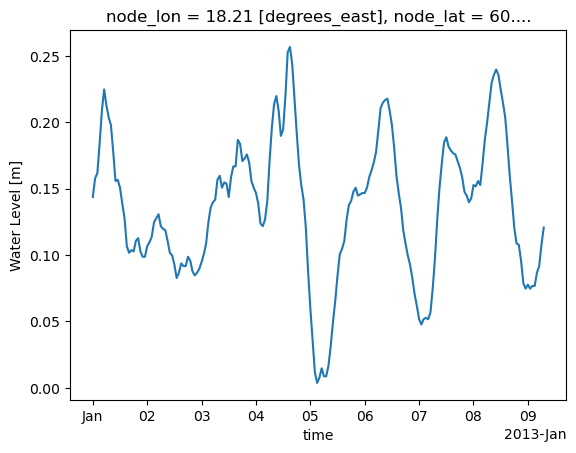

In [6]:
ds.waterlevel[:200, nc_idx].plot(x="time")

In [ ]:
obs = pd.read_csv("/home/olh001/Python/surgemip/data/obs/GESLA3/forsmark-2179-swe-smhi", 
                  comment="#", header=None, sep=r"\s+", 
                  parse_dates=[[0, 1],], date_format=r"%Y/%m/%d %H:%M:%S", usecols=(0, 1, 2))
obs = obs.set_index("0_1")

/tmp/ipykernel_3611616/3593936409.py:1: FutureWarning: Support for nested sequences for 'parse_dates' in pd.read_csv is deprecated. Combine the desired columns with pd.to_datetime after parsing instead.
  obs = pd.read_csv("/home/olh001/Python/surgemip/data/obs/GESLA3/forsmark-2179-swe-smhi",


<Axes: >

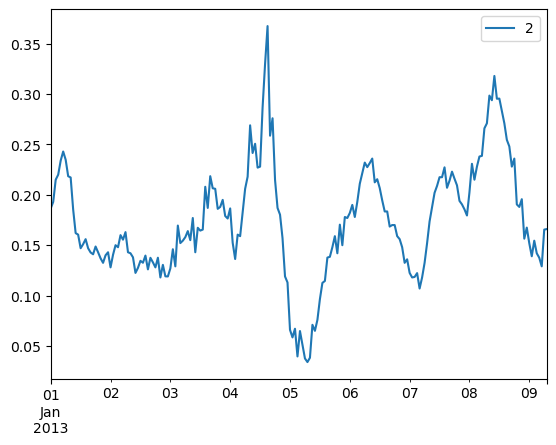

In [18]:
obs.loc[pd.to_datetime(ds.time[:200])].plot()

In [23]:
df_comp = pd.DataFrame.from_dict(
    {"obs": obs.loc[pd.to_datetime(ds.time[:200])].values.squeeze(),
     "mod": ds.waterlevel[:200, nc_idx].squeeze()}
)
df_comp.index = ds.time[:200].squeeze()

In [24]:
df_comp.hvplot.line()

:NdOverlay   [Variable]
   :Curve   [index]   (value)